In [19]:
import sys
sys.path.append("../")
sys.path.append("../../src")
from collision_scores import compute_collision_counts_and_length
from run_all_score_calculations import load_history_dump, reformat_history, filter_bat_positions_from_history
from supporting_files.utilities import load_parameters
from polarization_score import compute_polarization
import matplotlib.pyplot as plt
import numpy as np
from local_polarization_score import compute_local_polarization
from local_milling_score import compute_local_milling

def running_mean(x, N):
    cumsum = np.cumsum(np.insert(x, 0, 0)) 
    return (cumsum[N:] - cumsum[:-N]) / float(N)

In [2]:
dir = "/home/adityamoger/Documents/GitHub/bat-swarm-model/scripts/scores/16-41-44"
bat_positions_raw = load_history_dump(dir)
bat_positions_list, bat_directions_list= filter_bat_positions_from_history(bat_positions_raw)
parameters_df = load_parameters(dir+"/parameters_used.json")
print(compute_collision_counts_and_length(bat_positions_list, parameters_df))
polarization_list = [compute_polarization(bat_directions) for bat_directions in bat_directions_list]
local_polarization_list = [compute_local_polarization(bat_directions, bat_positions_list[i], parameters_df, 0.2) for i, bat_directions in enumerate(bat_directions_list)]

(17, 7, [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0

34980 58899
34980 58899
34980 58899
34980 58899
58899 58899
58899 58899
58899 58899
58899 58899


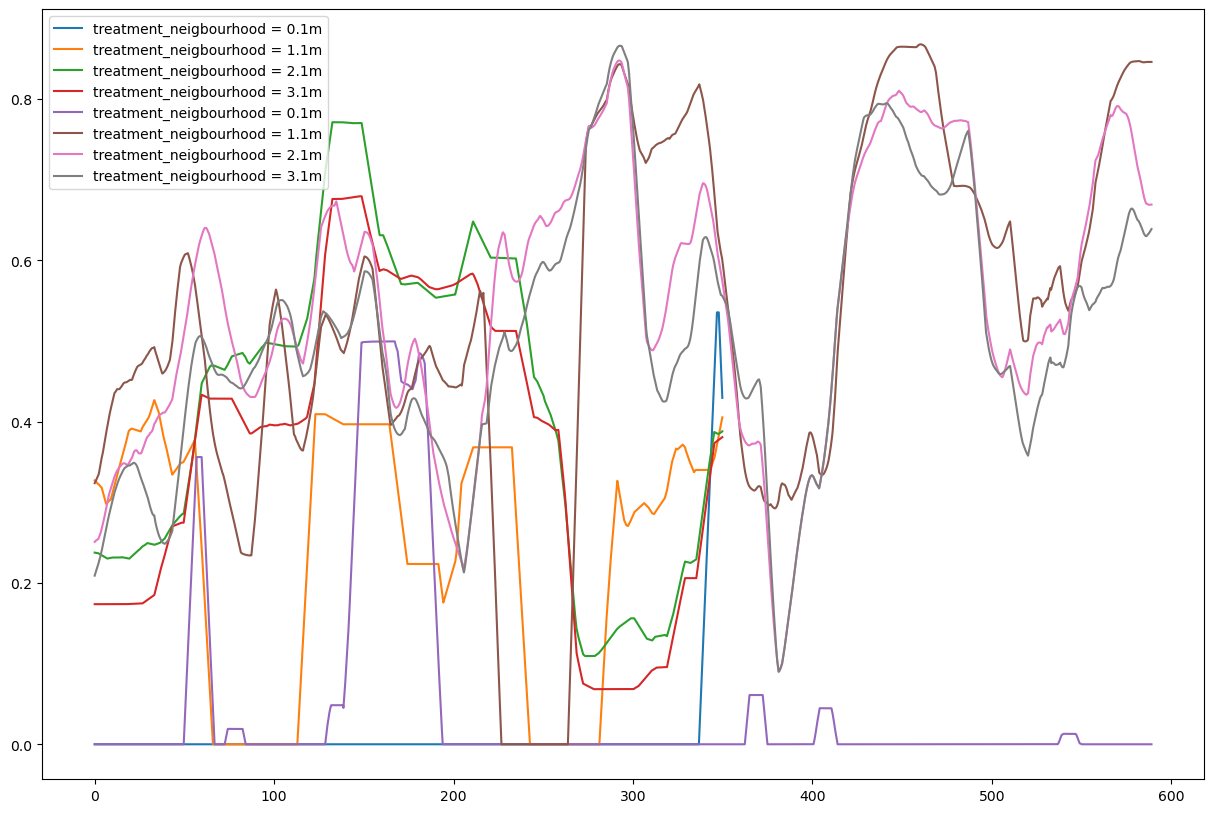

(0.0, 1.0)

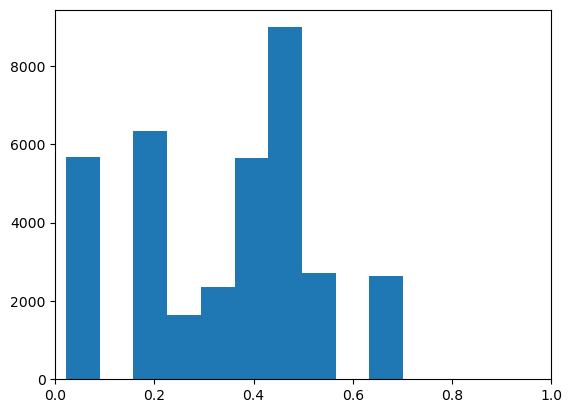

In [25]:
# plt.plot(polarization_list, )
import seaborn as sns
plt.figure(figsize=(15,10))

# for j in np.arange(0.1,4,1):
#     dir = "/home/adityamoger/Documents/GitHub/bat-swarm-model/scripts/scores/16-41-44"
#     bat_positions_raw = load_history_dump(dir)
#     bat_positions_list, bat_directions_list= filter_bat_positions_from_history(bat_positions_raw)
#     parameters_df = load_parameters(dir+"/parameters_used.json")
#     local_polarization_list = running_mean([compute_local_polarization(bat_directions, bat_positions_list[i], parameters_df, j) for i, bat_directions in enumerate(bat_directions_list)], 1000)
#     print(len(local_polarization_list) ,len(np.arange(0,len(local_polarization_list)/100, 0.01)))
#     sns.lineplot(x=np.arange(0,len(local_polarization_list)/100, 0.01) ,y=local_polarization_list, label = f"control_neigbourhood = {j}m", ls="-.")

for j in np.arange(0.1,4,1):
    dir = "/home/adityamoger/Documents/GitHub/bat-swarm-model/scripts/scores/16-41-44"
    bat_positions_raw = load_history_dump(dir)
    bat_positions_list, bat_directions_list= filter_bat_positions_from_history(bat_positions_raw)
    parameters_df = load_parameters(dir+"/parameters_used.json")
    local_polarization_list = running_mean([compute_local_polarization(bat_directions, bat_positions_list[i], parameters_df, j) for i, bat_directions in enumerate(bat_directions_list)], 1000)
    print(len(local_polarization_list) ,len(np.arange(0,588.99,0.01)))
    sns.lineplot(x=np.arange(0,len(local_polarization_list)/100, 0.01) ,y=local_polarization_list, label = f"treatment_neigbourhood = {j}m")

for j in np.arange(0.1,4,1):
    dir = "/home/adityamoger/Documents/GitHub/bat-swarm-model/scripts/scores/22-25-57"
    bat_positions_raw = load_history_dump(dir)
    bat_positions_list, bat_directions_list= filter_bat_positions_from_history(bat_positions_raw)
    parameters_df = load_parameters(dir+"/parameters_used.json")
    local_polarization_list = running_mean([compute_local_polarization(bat_directions, bat_positions_list[i], parameters_df, j) for i, bat_directions in enumerate(bat_directions_list)], 1000)
    print(len(local_polarization_list) ,len(np.arange(0,588.99,0.01)))
    sns.lineplot(x=np.arange(0,len(local_polarization_list)/100, 0.01) ,y=local_polarization_list, label = f"treatment_neigbourhood = {j}m")

plt.legend()
plt.show()
plt.hist(polarization_list)
plt.xlim(0,1)

34980 34980
33981 58899


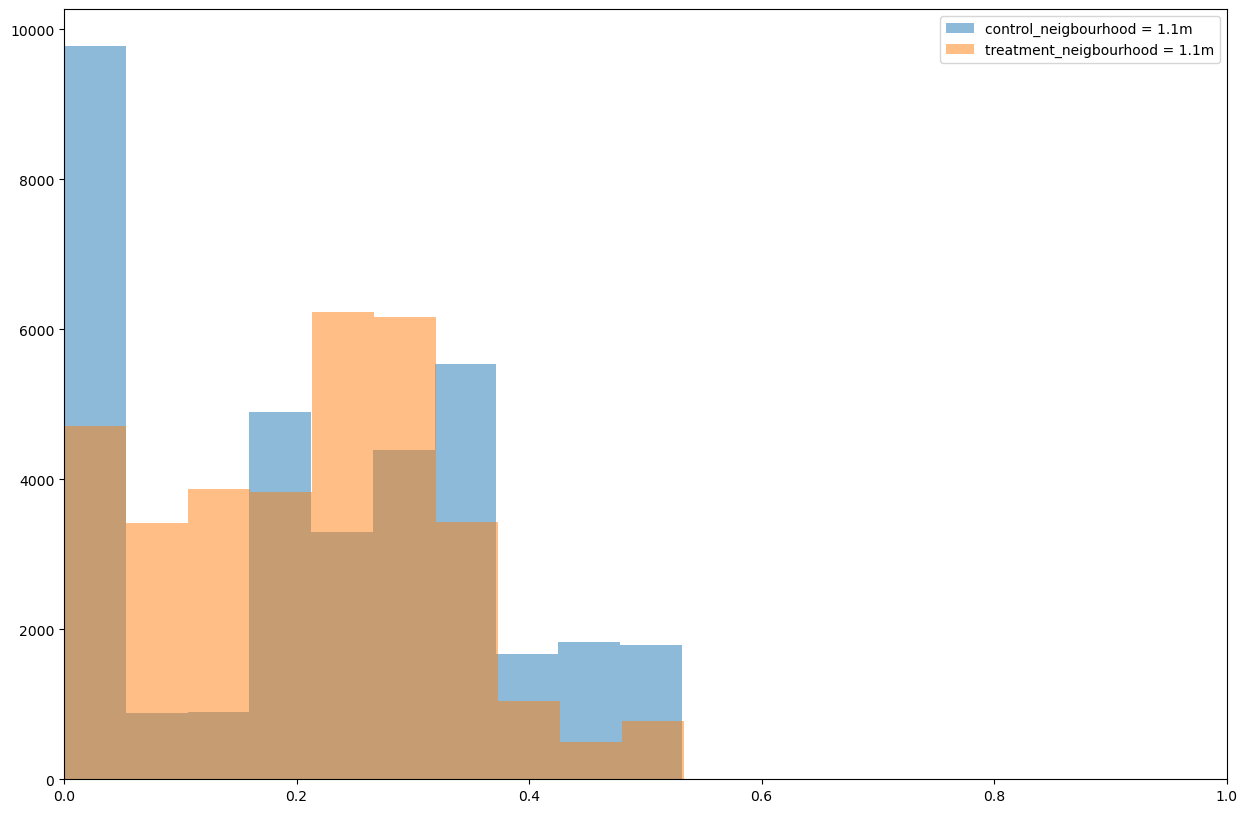

In [21]:
plt.figure(figsize=(15,10))

for j in [1.1]:#np.arange(0.1,4,1):
    dir = "/home/adityamoger/Documents/GitHub/bat-swarm-model/scripts/scores/16-41-44"
    bat_positions_raw = load_history_dump(dir)
    bat_positions_list, bat_directions_list= filter_bat_positions_from_history(bat_positions_raw)
    parameters_df = load_parameters(dir+"/parameters_used.json")
    local_polarization_list = running_mean([compute_local_milling(bat_directions, bat_positions_list[i], parameters_df, j) for i, bat_directions in enumerate(bat_directions_list)], 1000)
    print(len(local_polarization_list) ,len(np.arange(0,len(local_polarization_list)/100, 0.01)))
    plt.hist(local_polarization_list, label = f"control_neigbourhood = {j}m", ls="-.", alpha=0.5)

for j in [1.1]:#np.arange(0.1,4,1):
    dir = "/home/adityamoger/Documents/GitHub/bat-swarm-model/scripts/scores/22-25-57"
    bat_positions_raw = load_history_dump(dir)
    bat_positions_list, bat_directions_list= filter_bat_positions_from_history(bat_positions_raw)
    parameters_df = load_parameters(dir+"/parameters_used.json")
    bat_positions_list = bat_positions_list[:34980]
    bat_directions_list = bat_directions_list[:34980]
    local_polarization_list = running_mean([compute_local_milling(bat_directions, bat_positions_list[i], parameters_df, j) for i, bat_directions in enumerate(bat_directions_list)], 1000)
    print(len(local_polarization_list) ,len(np.arange(0,588.99,0.01)))
    plt.hist(local_polarization_list, label = f"treatment_neigbourhood = {j}m", alpha=0.5)

plt.xlim(0,1)
plt.legend()
plt.show()

34980 34980
33981 58899


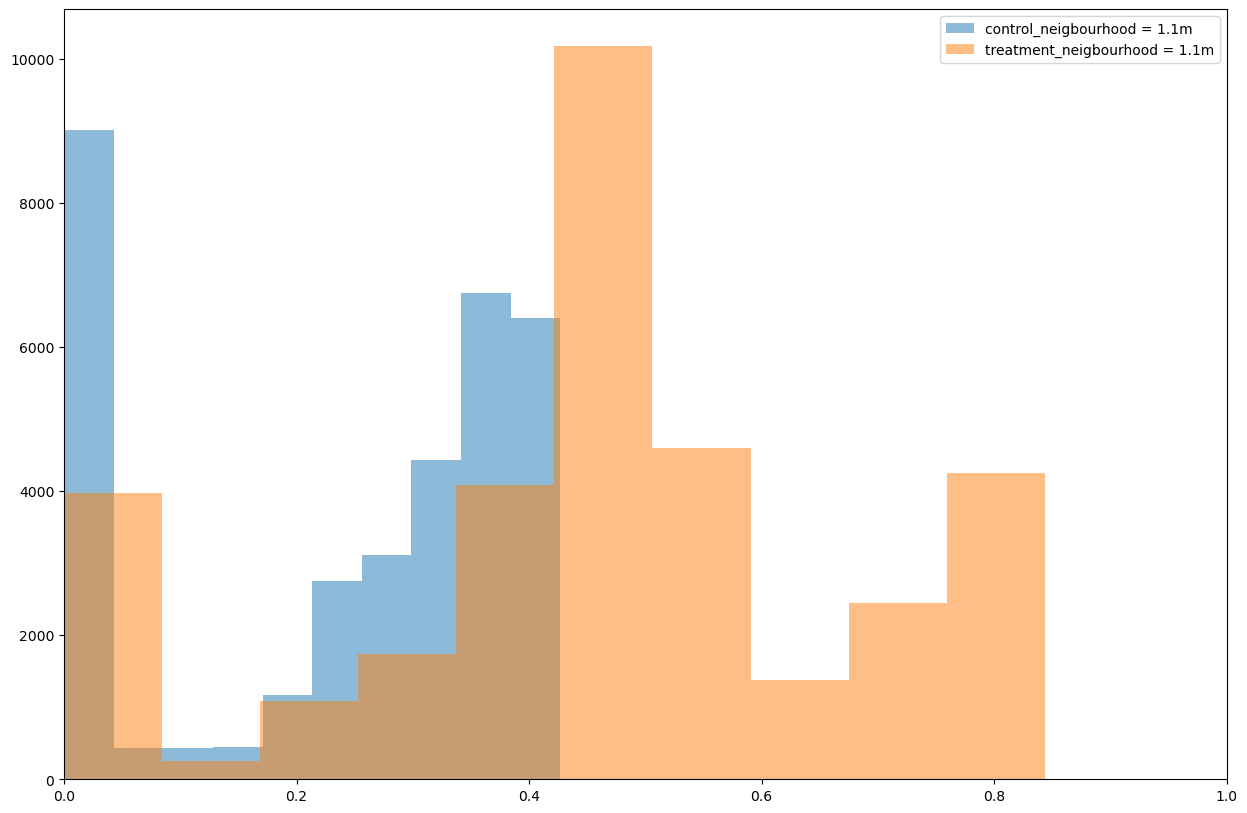

In [24]:
plt.figure(figsize=(15,10))

for j in [1.1]:#np.arange(0.1,4,1):
    dir = "/home/adityamoger/Documents/GitHub/bat-swarm-model/scripts/scores/16-41-44"
    bat_positions_raw = load_history_dump(dir)
    bat_positions_list, bat_directions_list= filter_bat_positions_from_history(bat_positions_raw)
    parameters_df = load_parameters(dir+"/parameters_used.json")
    local_polarization_list = running_mean([compute_local_polarization(bat_directions, bat_positions_list[i], parameters_df, j) for i, bat_directions in enumerate(bat_directions_list)], 1000)
    print(len(local_polarization_list) ,len(np.arange(0,len(local_polarization_list)/100, 0.01)))
    plt.hist(local_polarization_list, label = f"control_neigbourhood = {j}m", ls="-.", alpha=0.5)

for j in [1.1]:#np.arange(0.1,4,1):
    dir = "/home/adityamoger/Documents/GitHub/bat-swarm-model/scripts/scores/22-25-57"
    bat_positions_raw = load_history_dump(dir)
    bat_positions_list, bat_directions_list= filter_bat_positions_from_history(bat_positions_raw)
    parameters_df = load_parameters(dir+"/parameters_used.json")
    bat_positions_list = bat_positions_list[:34980]
    bat_directions_list = bat_directions_list[:34980]
    local_polarization_list = running_mean([compute_local_polarization(bat_directions, bat_positions_list[i], parameters_df, j) for i, bat_directions in enumerate(bat_directions_list)], 1000)
    print(len(local_polarization_list) ,len(np.arange(0,588.99,0.01)))
    plt.hist(local_polarization_list, label = f"treatment_neigbourhood = {j}m", alpha=0.5)

plt.xlim(0,1)
plt.legend()
plt.show()

34980 34980
33981 58899


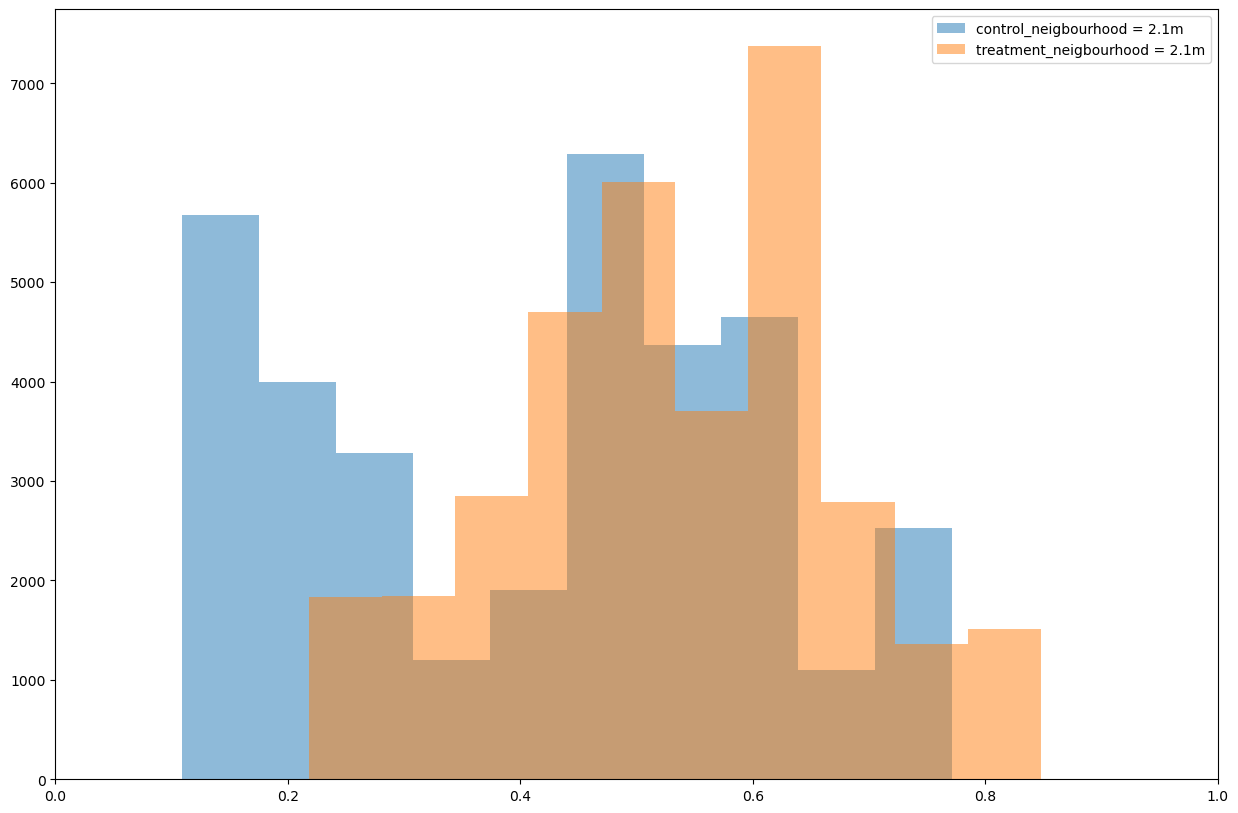

In [6]:
plt.figure(figsize=(15,10))

for j in [2.1]:#np.arange(0.1,4,1):
    dir = "/home/adityamoger/Documents/GitHub/bat-swarm-model/scripts/scores/16-41-44"
    bat_positions_raw = load_history_dump(dir)
    bat_positions_list, bat_directions_list= filter_bat_positions_from_history(bat_positions_raw)
    parameters_df = load_parameters(dir+"/parameters_used.json")
    local_polarization_list = running_mean([compute_local_polarization(bat_directions, bat_positions_list[i], parameters_df, j) for i, bat_directions in enumerate(bat_directions_list)], 1000)
    print(len(local_polarization_list) ,len(np.arange(0,len(local_polarization_list)/100, 0.01)))
    plt.hist(local_polarization_list, label = f"control_neigbourhood = {j}m", ls="-.", alpha=0.5)

for j in [2.1]:#np.arange(0.1,4,1):
    dir = "/home/adityamoger/Documents/GitHub/bat-swarm-model/scripts/scores/22-25-57"
    bat_positions_raw = load_history_dump(dir)
    bat_positions_list, bat_directions_list= filter_bat_positions_from_history(bat_positions_raw)
    parameters_df = load_parameters(dir+"/parameters_used.json")
    bat_positions_list = bat_positions_list[:34980]
    bat_directions_list = bat_directions_list[:34980]
    local_polarization_list = running_mean([compute_local_polarization(bat_directions, bat_positions_list[i], parameters_df, j) for i, bat_directions in enumerate(bat_directions_list)], 1000)
    print(len(local_polarization_list) ,len(np.arange(0,588.99,0.01)))
    plt.hist(local_polarization_list, label = f"treatment_neigbourhood = {j}m", alpha=0.5)

plt.xlim(0,1)
plt.legend()
plt.show()

34980 34980
33981 58899


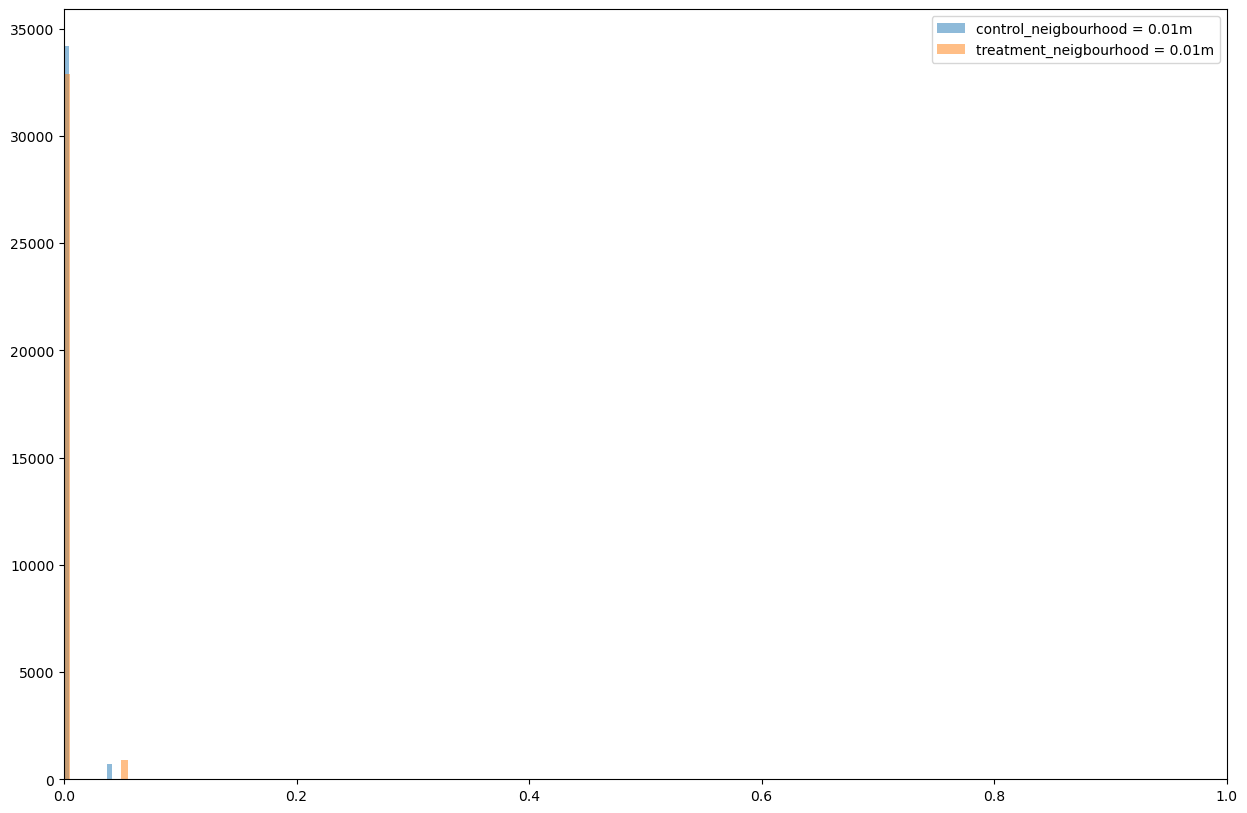

In [7]:
plt.figure(figsize=(15,10))

for j in [0.01]:#np.arange(0.1,4,1):
    dir = "/home/adityamoger/Documents/GitHub/bat-swarm-model/scripts/scores/16-41-44"
    bat_positions_raw = load_history_dump(dir)
    bat_positions_list, bat_directions_list= filter_bat_positions_from_history(bat_positions_raw)
    parameters_df = load_parameters(dir+"/parameters_used.json")
    local_polarization_list = running_mean([compute_local_polarization(bat_directions, bat_positions_list[i], parameters_df, j) for i, bat_directions in enumerate(bat_directions_list)], 1000)
    print(len(local_polarization_list) ,len(np.arange(0,len(local_polarization_list)/100, 0.01)))
    plt.hist(local_polarization_list, label = f"control_neigbourhood = {j}m", ls="-.", alpha=0.5)

for j in [0.01]:#np.arange(0.1,4,1):
    dir = "/home/adityamoger/Documents/GitHub/bat-swarm-model/scripts/scores/22-25-57"
    bat_positions_raw = load_history_dump(dir)
    bat_positions_list, bat_directions_list= filter_bat_positions_from_history(bat_positions_raw)
    parameters_df = load_parameters(dir+"/parameters_used.json")
    bat_positions_list = bat_positions_list[:34980]
    bat_directions_list = bat_directions_list[:34980]
    local_polarization_list = running_mean([compute_local_polarization(bat_directions, bat_positions_list[i], parameters_df, j) for i, bat_directions in enumerate(bat_directions_list)], 1000)
    print(len(local_polarization_list) ,len(np.arange(0,588.99,0.01)))
    plt.hist(local_polarization_list, label = f"treatment_neigbourhood = {j}m", alpha=0.5)

plt.xlim(0,1)
plt.legend()
plt.show()

34980 34980
33981 58899


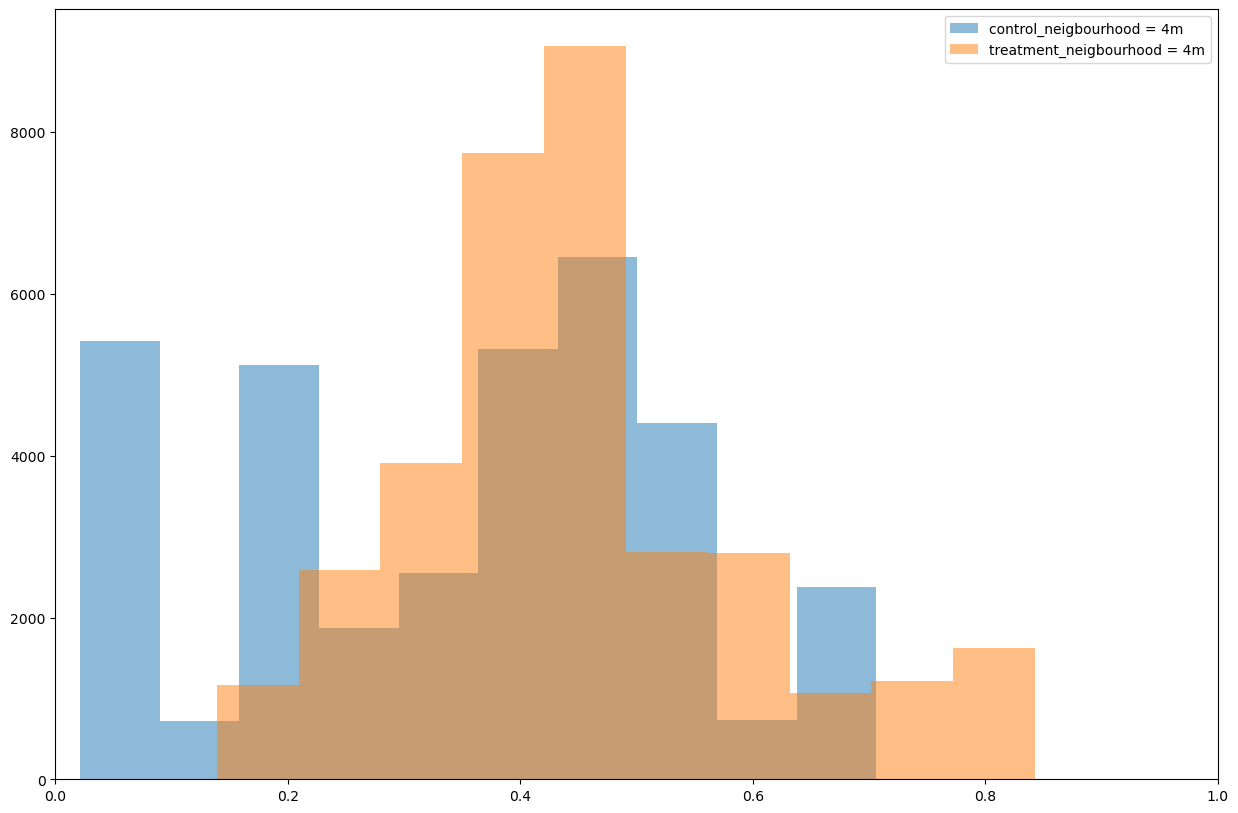

In [18]:
plt.figure(figsize=(15,10))

for j in [4]:#np.arange(0.1,4,1):
    dir = "/home/adityamoger/Documents/GitHub/bat-swarm-model/scripts/scores/16-41-44"
    bat_positions_raw = load_history_dump(dir)
    bat_positions_list, bat_directions_list= filter_bat_positions_from_history(bat_positions_raw)
    parameters_df = load_parameters(dir+"/parameters_used.json")
    local_polarization_list = running_mean([compute_local_polarization(bat_directions, bat_positions_list[i], parameters_df, j) for i, bat_directions in enumerate(bat_directions_list)], 1000)
    print(len(local_polarization_list) ,len(np.arange(0,len(local_polarization_list)/100, 0.01)))
    plt.hist(local_polarization_list, label = f"control_neigbourhood = {j}m", ls="-.", alpha=0.5)

for j in [4]:#np.arange(0.1,4,1):
    dir = "/home/adityamoger/Documents/GitHub/bat-swarm-model/scripts/scores/22-25-57"
    bat_positions_raw = load_history_dump(dir)
    bat_positions_list, bat_directions_list= filter_bat_positions_from_history(bat_positions_raw)
    parameters_df = load_parameters(dir+"/parameters_used.json")
    bat_positions_list = bat_positions_list[:34980]
    bat_directions_list = bat_directions_list[:34980]
    local_polarization_list = running_mean([compute_local_polarization(bat_directions, bat_positions_list[i], parameters_df, j) for i, bat_directions in enumerate(bat_directions_list)], 1000)
    print(len(local_polarization_list) ,len(np.arange(0,588.99,0.01)))
    plt.hist(local_polarization_list, label = f"treatment_neigbourhood = {j}m", alpha=0.5)

plt.xlim(0,1)
plt.legend()
plt.show()

In [8]:
np.mean(polarization_list), np.median(polarization_list)

(0.34175748, 0.40117356)

In [9]:
dir = "/home/adityamoger/Documents/GitHub/bat-swarm-model/scripts/scores/data/"
bat_positions_raw = load_history_dump(dir)
bat_positions, bat_directions= filter_bat_positions_from_history(bat_positions_raw)
parameters_df = load_parameters(dir+"/parameters_used.json")
compute_collision_counts_and_length(bat_positions, parameters_df)
polarization_list_control = compute_polarization(bat_directions)

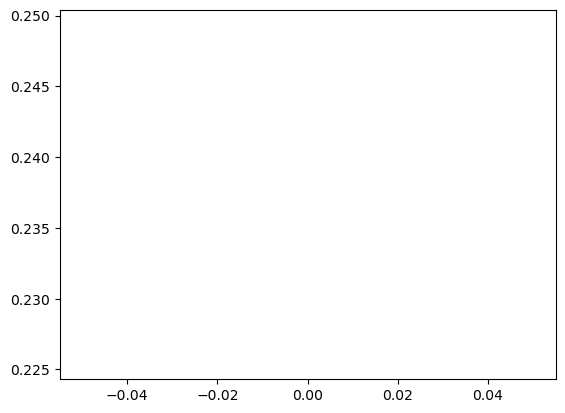

(0.0, 1.0)

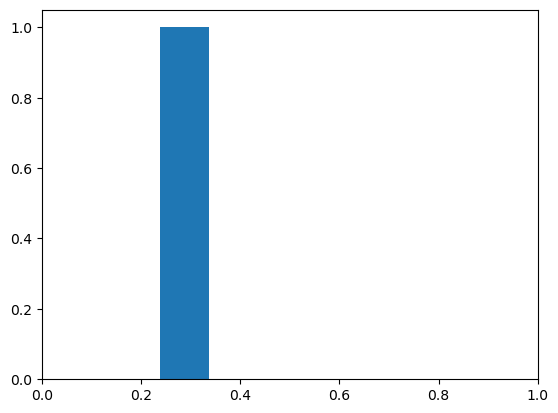

In [10]:


plt.plot(polarization_list_control)
plt.show()
plt.hist(polarization_list_control)
plt.xlim(0,1)


In [11]:
np.mean(polarization_list_control), np.median(polarization_list_control)

(0.23736255, 0.23736255)

{'bodies': [<matplotlib.collections.PolyCollection at 0x7172edd918b0>],
 'cmaxes': <matplotlib.collections.LineCollection at 0x7172edd91ca0>,
 'cmins': <matplotlib.collections.LineCollection at 0x7172edd91160>,
 'cbars': <matplotlib.collections.LineCollection at 0x7172edd93860>}

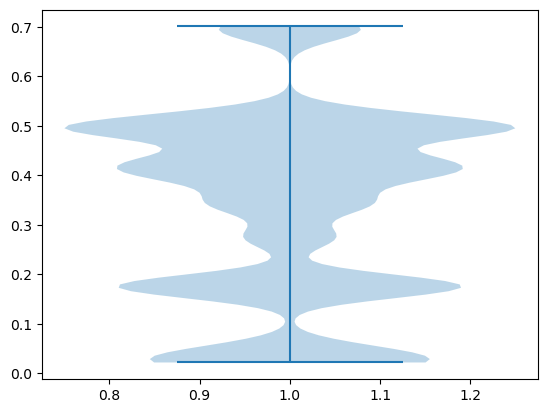

In [12]:
plt.violinplot(polarization_list)

In [13]:
import pandas as pd 
df = pd.DataFrame(columns = ["label", "scores"])
label_tr = ["treatment"] * len(polarization_list)
label_control = ["control"] * len(polarization_list_control)
label= []
scores = []
label.extend(label_control)
label.extend(label_tr)
scores.extend(polarization_list_control)
scores.extend(polarization_list)
df["label"]= label
df["scores"] = scores
df

TypeError: object of type 'numpy.float32' has no len()

<Axes: xlabel='label', ylabel='scores'>

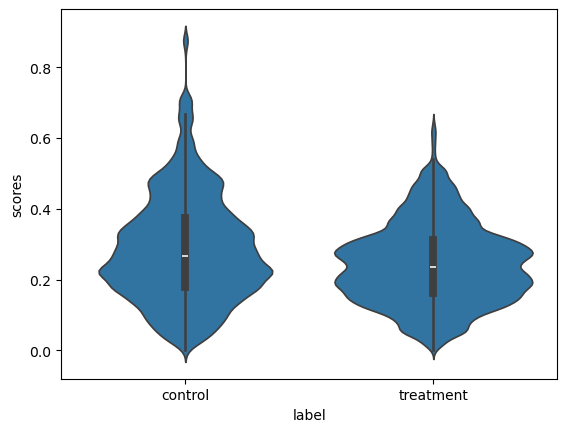

In [ ]:
import seaborn as sns
sns.violinplot(data=df, x="label", y="scores")

In [ ]:
from scores.calling_effort_score import calling_effort
from scores.collision_scores_single_bat import (
    compute_collision_counts_and_length,
    compute_collision_rate,
)
from scores.milling_score import compute_milling
from scores.nearest_neighbour_distance import compute_nearest_neighbour_distance
from scores.polarization_score import compute_polarization
from scores.space_occupied_scores import space_occupied_score

(60000, 10, 2)


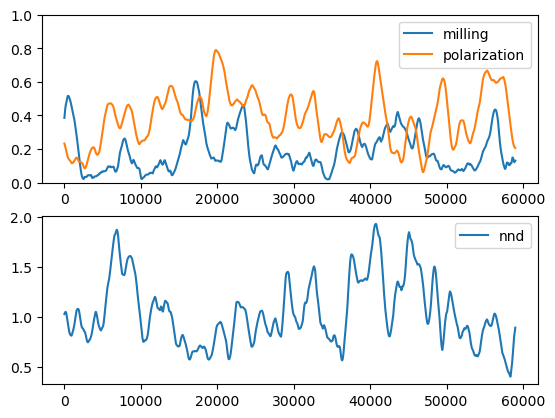

In [ ]:
output_dir = r"/home/adityamoger/Documents/GitHub/bat-swarm-model/multirun/2026-09-04/16-31-29/0/"
bat_positions_raw = load_history_dump(output_dir)
bat_positions, bat_directions = filter_bat_positions_from_history(bat_positions_raw)
x = np.array(bat_directions, dtype=np.half)
print(x.shape)

import matplotlib.pyplot as plt

def running_mean(x, N):
    cumsum = np.cumsum(np.insert(x, 0, 0))
    return (cumsum[N:] - cumsum[:-N]) / float(N)

milling_score_timeseries = compute_milling(
    bat_directions=bat_directions, bat_positions=bat_positions
)
polarization_score_timeseries = compute_polarization(bat_directions)
nnd_timeseries = compute_nearest_neighbour_distance(bat_positions)
median_nnd_time_series = np.median(nnd_timeseries, axis=1)

milling_score_timeseries = running_mean(milling_score_timeseries, 1000)
polarization_score_timeseries = running_mean(polarization_score_timeseries, 1000)
median_nnd_time_series = running_mean(median_nnd_time_series, 1000)
plt.subplot(2, 1, 1)
plt.plot(milling_score_timeseries, label="milling")
plt.plot(polarization_score_timeseries, label="polarization")
plt.ylim(0,1)
plt.legend()
plt.subplot(2, 1, 2)
plt.plot(median_nnd_time_series, label="nnd")
plt.legend()
plt.show()

(60000, 10, 2)


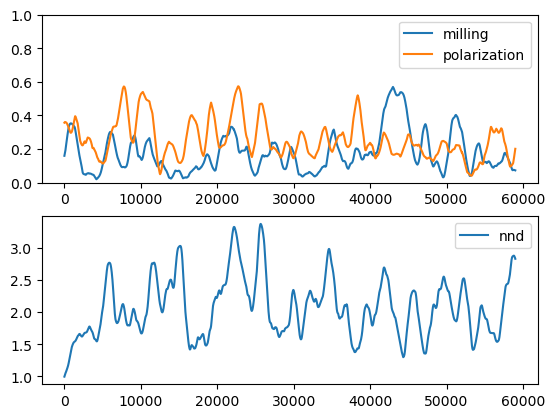

In [ ]:
output_dir = r"/home/adityamoger/Documents/GitHub/bat-swarm-model/multirun/2026-09-03/11-53-22/1/"
bat_positions_raw = load_history_dump(output_dir)
bat_positions, bat_directions = filter_bat_positions_from_history(bat_positions_raw)
x = np.array(bat_directions, dtype=np.half)
print(x.shape)

milling_score_timeseries_control = compute_milling(
    bat_directions=bat_directions, bat_positions=bat_positions
)
polarization_score_timeseries_control = compute_polarization(bat_directions)
nnd_timeseries_control = compute_nearest_neighbour_distance(bat_positions)
median_nnd_time_series_control = np.median(nnd_timeseries_control, axis=1)

milling_score_timeseries_control = running_mean(milling_score_timeseries_control, 1000)
polarization_score_timeseries_control = running_mean(polarization_score_timeseries_control, 1000)
median_nnd_time_series_control = running_mean(median_nnd_time_series_control, 1000)
plt.subplot(2, 1, 1)
plt.plot(milling_score_timeseries_control, label="milling")
plt.plot(polarization_score_timeseries_control, label="polarization")
plt.ylim(0,1)
plt.legend()
plt.subplot(2, 1, 2)
plt.plot(median_nnd_time_series_control, label="nnd")
plt.legend()
plt.show()

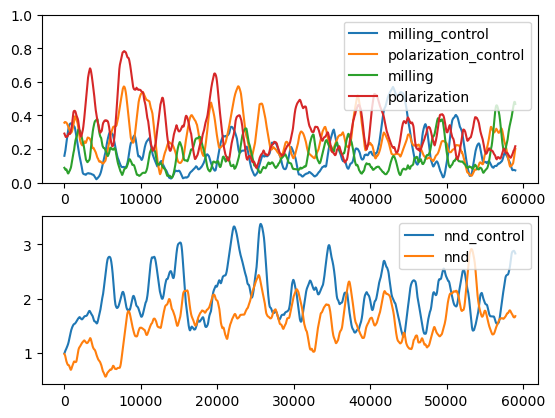

In [ ]:
plt.subplot(2, 1, 1)
plt.plot(milling_score_timeseries_control, label="milling_control")
plt.plot(polarization_score_timeseries_control, label="polarization_control")
plt.plot(milling_score_timeseries, label="milling")
plt.plot(polarization_score_timeseries, label="polarization")
plt.ylim(0,1)
plt.legend()
plt.subplot(2, 1, 2)
plt.plot(median_nnd_time_series_control, label="nnd_control")
plt.plot(median_nnd_time_series, label="nnd")
plt.legend()
plt.show()

